# 5 · Zero-shot forecasting with Chronos-2

[Chronos-2](https://huggingface.co/amazon/chronos-2) is a pretrained time-series foundation model. *Zero-shot* means the model is never trained or tuned on our data. We pass in the recent history of a series, and it returns a forecast with quantiles.

The structure follows the [building-demand tutorial](https://github.com/ShuaiGuo16/chronos-2-forecasting/blob/main/01_chronos2_zero_shot_building_demand_demo.ipynb) from ShuaiGuo16/chronos-2-forecasting, applied to the synthetic Graz station from [notebook 4](04_deep_learning_and_forecasting.ipynb). The question: given everything observed up to midnight, what will NO2 be over the next 24 hours? We ask it for each of the 50 days in the test period, score the forecasts with `nextaire_tools`, and compare them with a seasonal-naive baseline.

This notebook needs the `chronos-forecasting` package (`pip install chronos-forecasting`). The first run downloads the model weights from Hugging Face. The rest runs offline.

In [1]:
import sys, pathlib
# Reuse the synthetic data generator that ships with the reproductions.
sys.path.insert(0, str(pathlib.Path.cwd().parent / "reproductions"))

import importlib.util
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt

from _synthetic import make_graz_hourly

from nextaire_tools import Pipeline
from nextaire_tools.preprocessing import MissingValueHandler, OutlierHandler
from nextaire_tools.models import temporal_train_test_split, regression_metrics
from nextaire_tools.viz import INK, PALETTE, plot_predictions, set_style

set_style()
HAS_CHRONOS = importlib.util.find_spec("chronos") is not None
print(f"chronos-forecasting available: {HAS_CHRONOS}  (pip install chronos-forecasting)")

chronos-forecasting available: True  (pip install chronos-forecasting)


## Example data

The same synthetic station as notebook 4: `make_graz_hourly(n_days=200, seed=2)`, with NO2 as the target. The split is chronological. The last 25% (50 days) is held out for testing.

The cleaning pipeline is fitted on the training period only and then applied to the whole series, so the outlier thresholds never see test data. Chronos-2 normalises its inputs internally, so there is no scaler. Short gaps are interpolated and spikes are clipped, as in notebook 4. The model gets this cleaned series as input, but forecasts are scored against the raw measurements.

In [2]:
raw = make_graz_hourly(n_days=200, seed=2)
train_raw, test_raw = temporal_train_test_split(raw, test_size=0.25)

pipe = Pipeline([
    MissingValueHandler(strategy="interpolate", limit=3),
    OutlierHandler(columns=["no2", "o3", "pm10"], method="iqr", strategy="clip"),
    MissingValueHandler(strategy="bfill"),  # mop up any gap longer than the interpolate limit
])
pipe.fit(train_raw)  # outlier thresholds come from the training period only
clean = pipe.transform(raw)

target = "no2"
y = clean[target]          # cleaned series: the model's input
observed = raw[target]     # raw measurements: what forecasts are scored against
n_train = len(train_raw)
print("train:", len(train_raw), "hours  test:", len(test_raw), "hours  frequency:", pd.infer_freq(clean.index))

train: 3600 hours  test: 1200 hours  frequency: h


## Load the pretrained model

`Chronos2Pipeline.from_pretrained` loads the weights once. The notebook uses CUDA when it is available and the CPU otherwise.

In [3]:
if HAS_CHRONOS:
    import torch
    from chronos import Chronos2Pipeline

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map=device)
    print("loaded amazon/chronos-2 on", device)
else:
    model = None
    print("chronos-forecasting not installed: skipping the Chronos-2 sections")

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 19866.59it/s]

loaded amazon/chronos-2 on cpu


## Rolling day-ahead forecasts

Each test day gets its own forecast, issued at midnight. The model sees only the four weeks of cleaned NO2 available before that midnight. It predicts the next 24 hours with quantiles 0.05, 0.5, and 0.95. The 0.5 quantile is the median forecast, and the band between 0.05 and 0.95 is a 90% interval.

`predict_df` takes a long table with one row per series and timestamp. Each forecast origin becomes its own `item_id`, so all 50 forecasts run in a single call, which takes a few seconds on a laptop CPU.

In [4]:
HORIZON = 24       # hours to forecast
CONTEXT = 24 * 28  # hours of history the model sees: four weeks
QUANTILES = [0.05, 0.5, 0.95]

origins = range(n_train, len(y) - HORIZON + 1, HORIZON)  # midnight of each test day

history = pd.concat(
    [
        pd.DataFrame({
            "item_id": str(y.index[pos]),
            "timestamp": y.index[max(0, pos - CONTEXT):pos],
            target: y.iloc[max(0, pos - CONTEXT):pos].to_numpy(),
        })
        for pos in origins
    ],
    ignore_index=True,
)
print(f"{len(origins)} forecast origins, {len(history):,} history rows")

50 forecast origins, 33,600 history rows


In [5]:
if HAS_CHRONOS:
    forecasts = model.predict_df(
        history,
        prediction_length=HORIZON,
        quantile_levels=QUANTILES,
        id_column="item_id",
        timestamp_column="timestamp",
        target=target,
    )
    forecasts = forecasts.drop(columns=["target_name", "predictions"]).rename(
        columns={"0.05": "lower", "0.5": "median", "0.95": "upper"}
    )
    stamps = pd.DatetimeIndex(forecasts["timestamp"])
    forecasts["actual"] = observed.reindex(stamps).to_numpy()
    forecasts["naive"] = y.shift(HORIZON).reindex(stamps).to_numpy()  # same hour, previous day
    forecasts = forecasts.sort_values("timestamp").reset_index(drop=True)
else:
    forecasts = None
forecasts.head(6) if HAS_CHRONOS else None

,item_id,timestamp,lower,median,upper,actual,naive
0,2016-05-30 00:00:00,2016-05-30 00:00:00,0.659439,9.187541,18.455067,6.089891,11.742994
1,2016-05-30 00:00:00,2016-05-30 01:00:00,0.899733,9.678894,18.256809,9.433323,13.714919
2,2016-05-30 00:00:00,2016-05-30 02:00:00,0.891502,10.055028,19.055408,14.005610,5.401139
3,2016-05-30 00:00:00,2016-05-30 03:00:00,3.526800,12.778481,21.881983,10.712920,13.091567
4,2016-05-30 00:00:00,2016-05-30 04:00:00,4.415949,13.661416,22.852259,16.819867,9.188974
5,2016-05-30 00:00:00,2016-05-30 05:00:00,5.905571,15.641890,24.939157,10.842553,18.300289


## Scoring against a seasonal-naive baseline

The baseline predicts that each hour repeats the value from 24 hours earlier. Forecasts are scored against the raw measurements. Hours with no reading are skipped, and both the median forecast and the baseline are scored on the same hours. WAPE, the sum of absolute errors divided by the sum of observations, is a relative error, so it compares fairly across series with different NO2 levels.

In [6]:
if HAS_CHRONOS:
    scored = forecasts[forecasts["actual"].notna()]  # skip hours with no reading
    metric_names = ["mae", "rmse", "wape", "r2"]
    report = pd.DataFrame({
        "Chronos-2 (median)": regression_metrics(scored["actual"], scored["median"], metrics=metric_names),
        "seasonal naive": regression_metrics(scored["actual"], scored["naive"], metrics=metric_names),
    }).T.round(3)

    inside = (scored["actual"] >= scored["lower"]) & (scored["actual"] <= scored["upper"])
    print(f"Hours scored: {len(scored)} of {len(forecasts)}")
    print(f"Observations inside the 90% band: {inside.mean():.1%} (nominal 90%)")
else:
    report = None
report

Hours scored: 1191 of 1200
Observations inside the 90% band: 89.0% (nominal 90%)


,mae,rmse,wape,r2
Chronos-2 (median),4.936,6.271,0.217,0.779
seasonal naive,6.784,8.708,0.298,0.575


### One forecast day

The 11th test day, with the three days of history before its midnight origin. The shaded band is the 90% interval, and the dashed line is the seasonal-naive baseline.

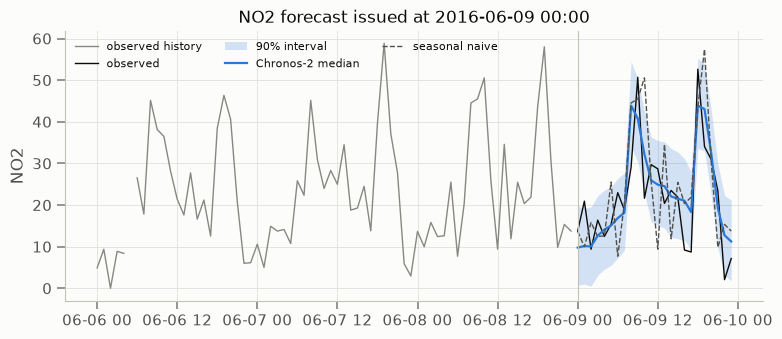

In [7]:
if HAS_CHRONOS:
    pos = origins[10]
    origin = y.index[pos]
    day = forecasts[forecasts["timestamp"].isin(y.index[pos:pos + HORIZON])]
    past = observed.iloc[pos - 72:pos]

    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.plot(past.index, past.to_numpy(), color=INK["muted"], lw=1, label="observed history")
    ax.plot(day["timestamp"], day["actual"], color=INK["primary"], lw=1, label="observed")
    ax.fill_between(day["timestamp"], day["lower"], day["upper"], color=PALETTE[0], alpha=0.2, label="90% interval")
    ax.plot(day["timestamp"], day["median"], color=PALETTE[0], lw=1.6, label="Chronos-2 median")
    ax.plot(day["timestamp"], day["naive"], color=INK["secondary"], lw=1, ls="--", label="seasonal naive")
    ax.axvline(origin, color=INK["baseline"], lw=0.8)
    ax.set_title(f"NO2 forecast issued at {origin:%Y-%m-%d %H:%M}")
    ax.set_ylabel("NO2")
    ax.legend(ncol=3, fontsize=8, frameon=False)
    plt.show()

### The full test period

The median forecast against the observations for all 50 days. Each day comes from its own forecast, so the line is a stitched series of 24-hour predictions.

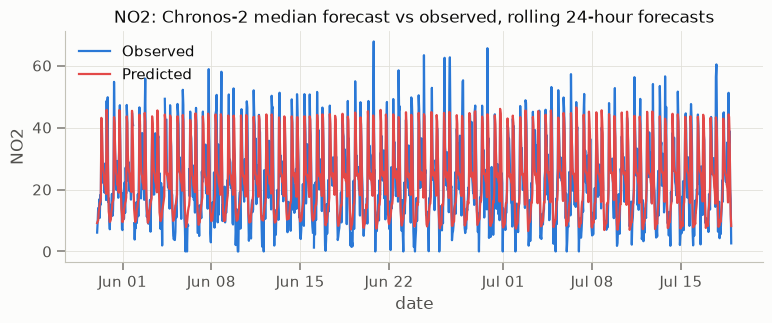

In [8]:
if HAS_CHRONOS:
    import matplotlib.dates as mdates

    ax = plot_predictions(
        forecasts["actual"],
        forecasts["median"],
        index=forecasts["timestamp"],
        kind="timeseries",
        figsize=(9, 3),
    )
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.set_title("NO2: Chronos-2 median forecast vs observed, rolling 24-hour forecasts")
    ax.set_xlabel("date")
    ax.set_ylabel("NO2")
    plt.show()

## Results

- Chronos-2 beats the seasonal-naive baseline on every metric in the table, and it does so without any training on this data.
- The 90% band contains close to 90% of the observations, so the intervals are roughly calibrated on this series.
- The synthetic series has a strong, regular daily cycle, which is easy to forecast. Results on real monitoring data will differ, so test any forecast on your own series before relying on it.

## Using your own series

Pass any regularly spaced hourly series as a long table with an `item_id`, a `timestamp`, and a value column. The same `predict_df` call works. Inputs known for the forecast period, such as weather forecasts or holidays, go in `future_df`. The tutorial linked at the top shows an example with covariates.

Back to **[1 · Quickstart](01_quickstart.ipynb)**, **[2 · Preprocessing & feature tour](02_preprocessing_and_features.ipynb)**, **[3 · Reproducing the papers](03_reproduce_papers.ipynb)**, or **[4 · Deep learning & Prophet forecasting](04_deep_learning_and_forecasting.ipynb)**.